
# HEIAuthRisk v1 — XGBoost + SHAP Analysis

Este notebook treina um **XGBoost** sobre a release pública do HEIAuthRisk v1 e utiliza **SHAP** para estudar como as variáveis contribuem para as decisões do modelo.

## Pergunta respondida

> Quais atributos do HEIAuthRisk v1 mais contribuem para um modelo XGBoost aprender a distinguir eventos com `provider_suspicious=1` daqueles com `provider_suspicious=0`?

## Interpretação correta

`provider_suspicious` é um **sinal operacional produzido pelo provedor**, não *ground truth* de ataque, fraude ou comprometimento.

Portanto:

- SHAP explica o comportamento do **modelo XGBoost**;
- a análise mostra associações aprendidas com o sinal do provedor;
- valores SHAP não demonstram causalidade;
- SHAP positivo desloca a saída do modelo em direção a `provider_suspicious=1`;
- SHAP negativo desloca a saída em direção a `provider_suspicious=0`.

O notebook usa somente o **dataset público de 42 atributos**, permitindo que a análise seja reproduzida externamente.

> **Nota:** esta versão utiliza apenas o *temporal holdout* principal. Não há *rolling temporal validation* neste notebook.



## 1. Dependências

Instale, se necessário:

```bash
pip install pandas numpy scipy scikit-learn xgboost shap matplotlib joblib
```

O notebook foi preparado para APIs recentes de `xgboost`, `shap` e `scikit-learn`.


In [7]:

from pathlib import Path
import os
import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import joblib
import xgboost as xgb
from xgboost import XGBClassifier
import shap

warnings.filterwarnings("ignore", category=FutureWarning)

print("pandas:", pd.__version__)
print("xgboost:", xgb.__version__)
print("shap:", shap.__version__)


pandas: 3.1.1
xgboost: 3.4.1
shap: 0.54.1


## 2. Configuração e localização do dataset

In [8]:

RANDOM_STATE = 42

# ------------------------------------------------------------
# SHAP scope
# ------------------------------------------------------------
# Recommended for the article:
#   "test" -> explain the complete held-out temporal test set.
#
# Optional:
#   "all"  -> explain all 73,526 events using the model trained
#             on the training partition. This is valid for studying
#             model behavior across the release, but it is NOT a
#             purely out-of-sample explanation because it includes
#             training/validation events.
SHAP_SCOPE = "test"  # "test" or "all"

# None = use every event in the selected SHAP_SCOPE.
# Set an integer (e.g. 2000) only if you intentionally want
# a smaller reproducible SHAP subset for faster exploration.
SHAP_MAX_ROWS = None

# Exact Tree SHAP is recommended for the article/test set.
# For SHAP_SCOPE="all", set True if you want a faster full-release run.
# Approximate Tree SHAP is faster but does not have the same
# consistency guarantees as exact Tree SHAP.
SHAP_APPROXIMATE = False

# Class weighting helps the classifier represent the minority class.
# When True, model scores should not automatically be interpreted
# as calibrated probabilities.
USE_CLASS_WEIGHT = True

TOP_N = 20

def locate_public_csv():
    override = os.environ.get("SUSPICIOUSLOGIN_PUBLIC_CSV")
    if override:
        path = Path(override).expanduser()
        if not path.exists():
            raise FileNotFoundError(path)
        return path.resolve()

    candidates = [
        Path("data/HEIAuthRisk_public_v1.csv"),
        Path("data/processed/HEIAuthRisk_public_v1.csv"),
        Path("../data/HEIAuthRisk_public_v1.csv"),
        Path("../data/processed/HEIAuthRisk_public_v1.csv"),
        Path("../../data/processed/HEIAuthRisk_public_v1.csv"),
        Path("/mnt/data/CIAuthE_v1_42_50_release/HEIAuthRisk_public_v1.csv"),
    ]
    for p in candidates:
        if p.exists():
            return p.resolve()

    raise FileNotFoundError(
        "HEIAuthRisk_public_v1.csv not found. "
        "Set SUSPICIOUSLOGIN_PUBLIC_CSV to the full path."
    )

PUBLIC_FILE = locate_public_csv()

output_override = os.environ.get("SUSPICIOUSLOGIN_XGB_SHAP_OUTPUT")
OUTPUT_DIR = (
    Path(output_override).expanduser().resolve()
    if output_override
    else PUBLIC_FILE.parent / "xgboost_shap_outputs"
)
FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

assert SHAP_SCOPE in {"test", "all"}
assert SHAP_MAX_ROWS is None or (
    isinstance(SHAP_MAX_ROWS, int) and SHAP_MAX_ROWS > 0
)

print("Dataset:", PUBLIC_FILE)
print("Outputs:", OUTPUT_DIR)
print("SHAP_SCOPE:", SHAP_SCOPE)
print("SHAP_MAX_ROWS:", SHAP_MAX_ROWS)
print("SHAP_APPROXIMATE:", SHAP_APPROXIMATE)


Dataset: E:\Developer\HEIAuthRisk\public\data\HEIAuthRisk_public_v1.csv
Outputs: E:\Developer\HEIAuthRisk\public\data\xgboost_shap_outputs
SHAP_SCOPE: test
SHAP_MAX_ROWS: None
SHAP_APPROXIMATE: False


## 3. Carregamento e verificações básicas

In [10]:

df = pd.read_csv(PUBLIC_FILE, low_memory=False)

assert len(df) == 73527, f"Eventos inesperados: {len(df)}"
assert len(df.columns) == 42, f"Colunas inesperadas: {len(df.columns)}"
assert df["event_id"].is_unique
assert "history_available" not in df.columns
assert df["provider_suspicious"].isna().sum() == 0
assert set(df["provider_suspicious"].astype(int).unique()) == {0, 1}

df["event_time_hour_utc"] = pd.to_datetime(
    df["event_time_hour_utc"],
    utc=True,
    format="mixed",
    errors="raise",
)

print("Shape:", df.shape)
print("Actors:", df["actor_pseudo_id"].nunique())
print("\nTarget distribution:")
display(
    df["provider_suspicious"]
    .value_counts()
    .rename_axis("provider_suspicious")
    .reset_index(name="events")
    .assign(percent=lambda x: x["events"] / len(df) * 100)
)


Shape: (73527, 42)
Actors: 12190

Target distribution:


,provider_suspicious,events,percent
0,0,66331,90.213119
1,1,7196,9.786881



## 4. Seleção das variáveis

Os identificadores não são usados como preditores:

- `event_id`
- `actor_pseudo_id`
- `actor_network_id`

O timestamp horário também é excluído como valor bruto, pois seus componentes temporais (`event_hour`, `day_of_week`, `month`, `is_weekend`) já estão disponíveis.

`provider_suspicious` é exclusivamente a variável-alvo.


In [11]:

TARGET = "provider_suspicious"

EXCLUDED_FEATURES = [
    "event_id",
    "actor_pseudo_id",
    "actor_network_id",
    "event_time_hour_utc",
    TARGET,
]

CATEGORICAL_FEATURES = [
    "ip_country",
    "continent",
    "login_type",
    "login_challenge_method",
]

FEATURES = [
    c for c in df.columns
    if c not in EXCLUDED_FEATURES
]

NUMERIC_FEATURES = [
    c for c in FEATURES
    if c not in CATEGORICAL_FEATURES
]

assert set(CATEGORICAL_FEATURES).issubset(FEATURES)
assert not (set(EXCLUDED_FEATURES) & set(FEATURES))

print("Model features:", len(FEATURES))
print("Numeric:", len(NUMERIC_FEATURES))
print("Categorical:", len(CATEGORICAL_FEATURES))

display(pd.DataFrame({
    "feature": FEATURES,
    "type": [
        "categorical" if c in CATEGORICAL_FEATURES else "numeric"
        for c in FEATURES
    ]
}))


Model features: 37
Numeric: 33
Categorical: 4


,feature,type
0,event_hour,numeric
1,day_of_week,numeric
2,month,numeric
3,is_weekend,numeric
4,prior_event_count,numeric
5,hours_since_last_login,numeric
6,hours_since_first_login,numeric
7,logins_24h,numeric
8,logins_7d,numeric
9,logins_30d,numeric



## 5. Divisão temporal treino / validação / teste

Não é usado *random split*.

Os eventos são ordenados por `event_time_hour_utc` e separados aproximadamente em:

- 70% treino;
- 15% validação;
- 15% teste.

O corte respeita horas completas: a mesma hora UTC não é dividida entre conjuntos diferentes.


In [12]:

df_model = df.sort_values(
    ["event_time_hour_utc", "event_id"],
    kind="mergesort",
).reset_index(drop=True)

n = len(df_model)
candidate_70 = df_model.loc[int(n * 0.70), "event_time_hour_utc"]
candidate_85 = df_model.loc[int(n * 0.85), "event_time_hour_utc"]

train_mask = df_model["event_time_hour_utc"] < candidate_70
valid_mask = (
    (df_model["event_time_hour_utc"] >= candidate_70)
    & (df_model["event_time_hour_utc"] < candidate_85)
)
test_mask = df_model["event_time_hour_utc"] >= candidate_85

train = df_model.loc[train_mask].copy()
valid = df_model.loc[valid_mask].copy()
test = df_model.loc[test_mask].copy()

for name, part in [("train", train), ("validation", valid), ("test", test)]:
    assert len(part) > 0
    assert part[TARGET].nunique() == 2
    print(
        f"{name:10s}: {len(part):6,d} events | "
        f"{part[TARGET].mean()*100:6.2f}% provider_suspicious=1 | "
        f"{part['event_time_hour_utc'].min()} -> "
        f"{part['event_time_hour_utc'].max()}"
    )

assert train["event_time_hour_utc"].max() < valid["event_time_hour_utc"].min()
assert valid["event_time_hour_utc"].max() < test["event_time_hour_utc"].min()


train     : 51,461 events |  10.05% provider_suspicious=1 | 2025-12-19 19:00:00+00:00 -> 2026-06-02 06:00:00+00:00
validation: 11,033 events |  11.19% provider_suspicious=1 | 2026-06-02 07:00:00+00:00 -> 2026-06-20 03:00:00+00:00
test      : 11,033 events |   7.14% provider_suspicious=1 | 2026-06-20 04:00:00+00:00 -> 2026-08-12 16:00:00+00:00


## 6. Pré-processamento

In [13]:

numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=False,
        ),
    ),
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent",
        ),
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True,
        ),
    ),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, NUMERIC_FEATURES),
        ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
    ],
    remainder="drop",
    sparse_threshold=1.0,
)

X_train = train[FEATURES]
y_train = train[TARGET].astype(int)

X_valid = valid[FEATURES]
y_valid = valid[TARGET].astype(int)

X_test = test[FEATURES]
y_test = test[TARGET].astype(int)

X_train_t = preprocessor.fit_transform(X_train)
X_valid_t = preprocessor.transform(X_valid)
X_test_t = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out().tolist()

print("Transformed train shape:", X_train_t.shape)
print("Transformed features:", len(feature_names))


Transformed train shape: (51461, 104)
Transformed features: 104


## 7. Treinamento do XGBoost

In [14]:

negative = int((y_train == 0).sum())
positive = int((y_train == 1).sum())

scale_pos_weight = (
    negative / positive
    if USE_CLASS_WEIGHT
    else 1.0
)

print("scale_pos_weight:", scale_pos_weight)

# Modifique a instanciação do XGBClassifier na Célula 7:
model = XGBClassifier(
    n_estimators=1000,           # Aumentamos o teto, mas o Early Stopping controla
    max_depth=6,                 # Aumentado de 4 para 6 para capturar regras mais complexas
    learning_rate=0.03,          # Taxa menor para um aprendizado mais refinado
    min_child_weight=2,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    scale_pos_weight=scale_pos_weight,
    early_stopping_rounds=30,    # Para o treino se não melhorar após 30 árvores
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# O comando de fit permanece igual
model.fit(
    X_train_t,
    y_train,
    eval_set=[
        (X_train_t, y_train),
        (X_valid_t, y_valid),
    ],
    verbose=False,
)

print("XGBoost training complete com Early Stopping.")


scale_pos_weight: 8.947999226754302
XGBoost training complete com Early Stopping.


## 8. Desempenho no conjunto de teste

ROC-AUC: 0.8999
PR-AUC:  0.4007

Relatório de Classificação (Threshold Otimizado = 0.3467):
              precision    recall  f1-score   support

           0     0.9679    0.9043    0.9351     10245
           1     0.3292    0.6104    0.4277       788

    accuracy                         0.8833     11033
   macro avg     0.6486    0.7574    0.6814     11033
weighted avg     0.9223    0.8833    0.8988     11033



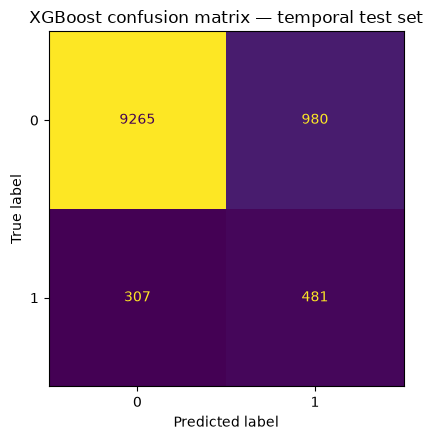

In [15]:

from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score, average_precision_score

# 1. Obter probabilidades e calcular métricas globais
test_probability = model.predict_proba(X_test_t)[:, 1]
roc_auc = roc_auc_score(y_test, test_probability)
pr_auc = average_precision_score(y_test, test_probability)

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC:  {pr_auc:.4f}\n")

# 2. Encontrar o melhor threshold matematicamente usando o F1-Score
precisions, recalls, thresholds = precision_recall_curve(y_test, test_probability)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

# 3. Aplicar o limiar otimizado
test_prediction = (test_probability >= best_threshold).astype(int)

print(f"Relatório de Classificação (Threshold Otimizado = {best_threshold:.4f}):")
print(classification_report(y_test, test_prediction, digits=4))


performance = pd.DataFrame([
    {
        "metric": "ROC-AUC",
        "value": roc_auc,
    },
    {
        "metric": "PR-AUC / Average Precision",
        "value": pr_auc,
    },
    {
        "metric": "Test positive prevalence",
        "value": y_test.mean(),
    },
])

performance.to_csv(
    OUTPUT_DIR / "xgboost_test_performance.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(5.2, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, test_prediction),
    display_labels=[0, 1],
).plot(ax=ax, colorbar=False)
ax.set_title("XGBoost confusion matrix — temporal test set")
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "xgboost_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()



## 9. Interpretable Modeling Support with XGBoost SHAP

Por padrão, a análise SHAP é calculada sobre **todo o conjunto temporal de teste**
(`SHAP_SCOPE="test"` e `SHAP_MAX_ROWS=None`).

Isso mantém a explicação principal fora da amostra utilizada no ajuste do modelo.

Opcionalmente:

- `SHAP_SCOPE="all"` calcula SHAP para todos os eventos da release;
- `SHAP_MAX_ROWS=2000` (ou outro inteiro) reduz o número de eventos explicados de forma reproduzível.

O uso de `SHAP_SCOPE="all"` é útil para descrever o comportamento do modelo em toda a release, mas inclui eventos de treino e validação e, portanto, não deve ser apresentado como explicação exclusivamente *out-of-sample*.


In [16]:

rng = np.random.default_rng(RANDOM_STATE)

if SHAP_SCOPE == "test":
    X_scope_original = X_test.copy()
    y_scope = y_test.copy()
    X_scope_t = X_test_t
    scope_name = "temporal test set"
    metadata_scope = test[["event_id", "event_time_hour_utc", TARGET]].copy()
else:
    X_scope_original = df_model[FEATURES].copy()
    y_scope = df_model[TARGET].astype(int).copy()
    X_scope_t = preprocessor.transform(X_scope_original)
    scope_name = "full dataset"
    metadata_scope = df_model[["event_id", "event_time_hour_utc", TARGET]].copy()

scope_size = len(X_scope_original)

if SHAP_MAX_ROWS is None or SHAP_MAX_ROWS >= scope_size:
    sample_positions = np.arange(scope_size)
else:
    sample_positions = np.sort(
        rng.choice(
            np.arange(scope_size),
            size=SHAP_MAX_ROWS,
            replace=False,
        )
    )

X_shap_original = X_scope_original.iloc[sample_positions].copy()
y_shap = y_scope.iloc[sample_positions].copy()
metadata_shap = metadata_scope.iloc[sample_positions].reset_index(drop=True)
X_shap_t = X_scope_t[sample_positions]

# Dense values are used for SHAP plots and feature-value colouring.
# With the current v1.0 schema this remains manageable for the full release.
if sparse.issparse(X_shap_t):
    X_shap_dense = X_shap_t.toarray()
else:
    X_shap_dense = np.asarray(X_shap_t)

shap_n = len(X_shap_original)

print("SHAP scope:", scope_name)
print("Available events in scope:", scope_size)
print("Events explained by SHAP:", shap_n)
print("Transformed SHAP matrix:", X_shap_dense.shape)
print(
    "provider_suspicious=1 in explained events:",
    f"{y_shap.mean()*100:.2f}%"
)


SHAP scope: temporal test set
Available events in scope: 11033
Events explained by SHAP: 11033
Transformed SHAP matrix: (11033, 104)
provider_suspicious=1 in explained events: 7.14%



## 10. Global explanation of feature importance

A análise global utiliza contribuições SHAP exatas calculadas pelo próprio XGBoost (`pred_contribs=True`) sobre a **mesma matriz sparse** utilizada pelo modelo. A propriedade aditiva é validada numericamente contra o *raw margin* do XGBoost.

Para o artigo:

- valores SHAP positivos deslocam a saída em direção a `provider_suspicious=1`;
- valores SHAP negativos deslocam a saída em direção a `provider_suspicious=0`;
- magnitude SHAP representa contribuição para o modelo, não causalidade.

### Agregação das variáveis categóricas

Para retornar das colunas *one-hot* às variáveis originais do CIAuthE, as contribuições SHAP das categorias de uma mesma variável são **somadas em cada evento**. Só então é calculado `mean(|SHAP agrupado|)`.

Esse procedimento preserva a aditividade no nível da variável original e evita interpretar cada dummy como se fosse uma variável independente do dataset.


In [17]:

# ============================================================
# Exact SHAP contributions on the SAME sparse representation
# used by XGBoost for prediction.
# ============================================================
# Important: the model was trained on a scipy sparse matrix.
# Converting the transformed matrix to dense before explanation can
# change XGBoost's missing-value semantics. Therefore, the article
# analysis uses XGBoost's exact pred_contribs on X_shap_t itself.

shap_dmatrix = xgb.DMatrix(X_shap_t)

contributions = model.get_booster().predict(
    shap_dmatrix,
    pred_contribs=True,
    approx_contribs=SHAP_APPROXIMATE,
)

# Last column is the base/bias term.
shap_matrix = contributions[:, :-1]
shap_base_values = contributions[:, -1]

# Verify SHAP additivity against the raw XGBoost margin.
raw_margin = model.get_booster().predict(
    shap_dmatrix,
    output_margin=True,
)

shap_additivity_error = float(
    np.max(
        np.abs(
            shap_matrix.sum(axis=1)
            + shap_base_values
            - raw_margin
        )
    )
)

assert shap_additivity_error < 1e-4, (
    f"Unexpected SHAP additivity error: {shap_additivity_error}"
)

# Dense values are used ONLY as display data in SHAP plots.
# The contributions themselves were computed on the sparse matrix.
if sparse.issparse(X_shap_t):
    X_shap_dense = X_shap_t.toarray()
else:
    X_shap_dense = np.asarray(X_shap_t)

clean_feature_names = [
    name.replace("num__", "", 1).replace("cat__", "", 1)
    for name in feature_names
]

shap_values = shap.Explanation(
    values=shap_matrix,
    base_values=shap_base_values,
    data=X_shap_dense,
    feature_names=clean_feature_names,
)

print("SHAP backend: XGBoost pred_contribs")
print("SHAP values shape:", shap_values.values.shape)
print("Maximum additivity error:", shap_additivity_error)
print("Expected/base value example:", shap_values.base_values[0])

# Compact labels used ONLY in figures.
def compact_plot_label(name):
    replacements = [
        ("login_challenge_method_", "challenge: "),
        ("login_type_", "login type: "),
        ("idv_preregistered_phone", "IDV prereg. phone"),
        ("idv_preregistered_email", "IDV prereg. email"),
        ("knowledge_preregistered_phone", "knowledge prereg. phone"),
        ("device_prompt", "device prompt"),
        ("offline_otp", "offline OTP"),
        ("google_password", "Google password"),
    ]
    label = str(name)
    for old, new in replacements:
        label = label.replace(old, new)
    return label.replace("|", " + ")

plot_feature_names = [
    compact_plot_label(name)
    for name in clean_feature_names
]

shap_values_plot = shap.Explanation(
    values=shap_values.values,
    base_values=shap_values.base_values,
    data=shap_values.data,
    feature_names=plot_feature_names,
)


SHAP backend: XGBoost pred_contribs
SHAP values shape: (11033, 104)
Maximum additivity error: 1.9073486328125e-05
Expected/base value example: 0.06357639


## 11. Importância global — variáveis transformadas

In [18]:

mean_abs_shap = np.abs(shap_values.values).mean(axis=0)

encoded_importance = (
    pd.DataFrame({
        "transformed_feature": clean_feature_names,
        "mean_abs_shap": mean_abs_shap,
    })
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

encoded_importance.to_csv(
    OUTPUT_DIR / "shap_global_encoded_features.csv",
    index=False,
)

display(encoded_importance.head(TOP_N))


,transformed_feature,mean_abs_shap
0,login_type_exchange,0.795219
1,networks_seen_to_date,0.757044
2,is_new_ip,0.632522
3,distinct_networks_30d,0.507633
4,prior_event_count,0.476376
5,login_type_reauth,0.423502
6,ip_country_Brazil,0.411994
7,login_challenge_method_none,0.394303
8,distinct_login_types_30d,0.393471
9,event_hour,0.365038


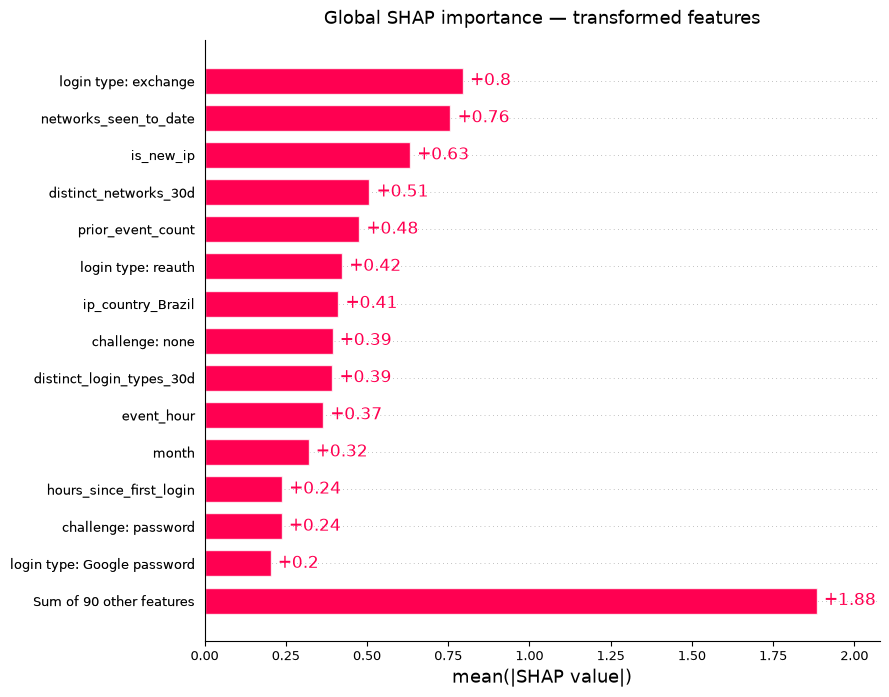

In [19]:

shap.plots.bar(
    shap_values_plot,
    max_display=15,
    show=False,
)

fig = plt.gcf()
fig.set_size_inches(12.5, 7.6)

ax = plt.gca()
ax.set_title(
    "Global SHAP importance — transformed features",
    fontsize=13,
    pad=12,
)
ax.tick_params(axis="y", labelsize=9)
ax.tick_params(axis="x", labelsize=9)

fig.subplots_adjust(
    left=0.43,
    right=0.97,
    top=0.91,
    bottom=0.12,
)

fig.savefig(
    FIGURE_DIR / "shap_global_bar_transformed.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "shap_global_bar_transformed.pdf",
    bbox_inches="tight",
)
plt.show()



## 12. Beeswarm — magnitude e direção

O *beeswarm* mostra simultaneamente:

- quais variáveis têm maior contribuição;
- se a contribuição tende a empurrar o modelo para a classe 1 ou classe 0;
- a distribuição das contribuições entre eventos.

Para variáveis one-hot, o gráfico mostra categorias específicas, como `ip_country_Angola` ou `login_type_reauth`.


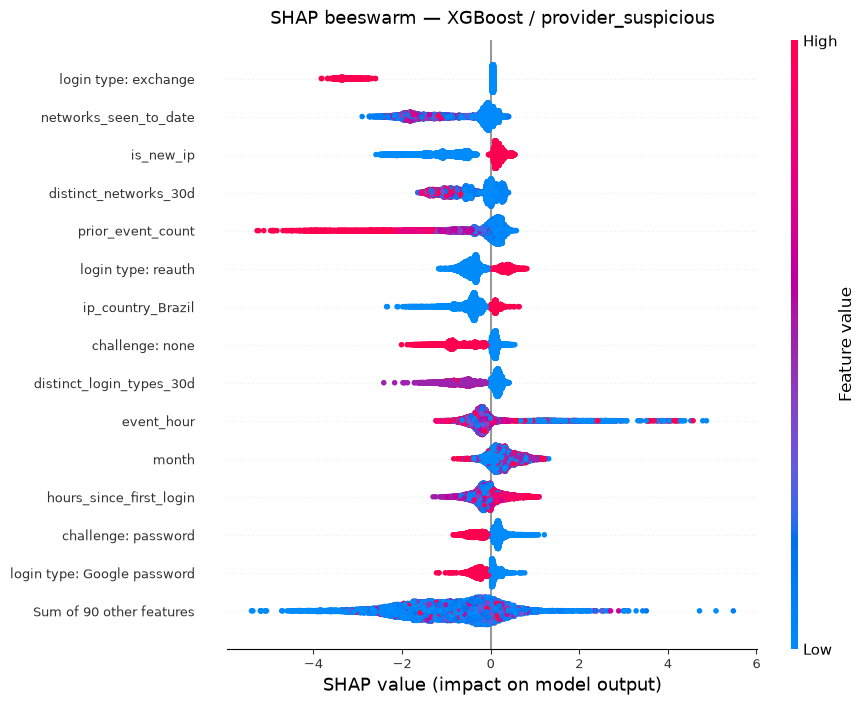

In [20]:

shap.plots.beeswarm(
    shap_values_plot,
    max_display=15,
    plot_size=(12.5, 7.8),
    show=False,
)

fig = plt.gcf()
ax = plt.gca()

ax.set_title(
    "SHAP beeswarm — XGBoost / provider_suspicious",
    fontsize=13,
    pad=12,
)
ax.tick_params(axis="y", labelsize=9)
ax.tick_params(axis="x", labelsize=9)

fig.subplots_adjust(
    left=0.40,
    right=0.93,
    top=0.91,
    bottom=0.13,
)

fig.savefig(
    FIGURE_DIR / "shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "shap_beeswarm.pdf",
    bbox_inches="tight",
)
plt.show()



## 13. Agregação SHAP para as variáveis originais

O One-Hot Encoding transforma uma variável categórica em várias colunas. Para responder à pergunta “qual variável original mais contribui?”, os valores `mean(|SHAP|)` das categorias derivadas de uma mesma variável são somados.

Isso produz uma importância por atributo do dataset, em vez de uma importância por dummy.


In [21]:

def source_variable_from_transformed_name(name):
    if name in NUMERIC_FEATURES:
        return name

    for col in sorted(
        CATEGORICAL_FEATURES,
        key=len,
        reverse=True,
    ):
        if name.startswith(col + "_"):
            return col

    return name


# Correct mapping follows each transformed feature name, not dataframe row order.
encoded_importance["source_variable"] = (
    encoded_importance["transformed_feature"]
    .map(source_variable_from_transformed_name)
)

# Diagnostic only: sum of mean absolute SHAP values in encoded space.
source_encoded_abs_sum = (
    encoded_importance
    .groupby("source_variable", as_index=False)["mean_abs_shap"]
    .sum()
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)
source_encoded_abs_sum["relative_percent"] = (
    source_encoded_abs_sum["mean_abs_shap"]
    / source_encoded_abs_sum["mean_abs_shap"].sum()
    * 100
)
source_encoded_abs_sum.to_csv(
    OUTPUT_DIR / "shap_source_variables_encoded_abs_sum_DIAGNOSTIC.csv",
    index=False,
)

# Primary article aggregation: sum SHAP by original variable PER EVENT,
# then calculate mean(abs(grouped contribution)).
transformed_to_source = [
    source_variable_from_transformed_name(name)
    for name in clean_feature_names
]
source_variables = list(dict.fromkeys(transformed_to_source))
source_index = {name: j for j, name in enumerate(source_variables)}

source_shap_matrix = np.zeros(
    (shap_values.values.shape[0], len(source_variables)),
    dtype=float,
)

for transformed_j, source_name in enumerate(transformed_to_source):
    source_shap_matrix[:, source_index[source_name]] += (
        shap_values.values[:, transformed_j]
    )

source_importance = pd.DataFrame({
    "source_variable": source_variables,
    "mean_abs_shap": np.mean(np.abs(source_shap_matrix), axis=0),
})

source_importance = (
    source_importance
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

source_importance["relative_percent"] = (
    source_importance["mean_abs_shap"]
    / source_importance["mean_abs_shap"].sum()
    * 100
)

source_importance.to_csv(
    OUTPUT_DIR / "shap_global_source_variables.csv",
    index=False,
)

display(source_importance.head(TOP_N))


,source_variable,mean_abs_shap,relative_percent
0,login_type,1.336068,17.847343
1,networks_seen_to_date,0.757044,10.112675
2,is_new_ip,0.632522,8.449296
3,distinct_networks_30d,0.507633,6.781018
4,prior_event_count,0.476376,6.363480
5,login_challenge_method,0.461701,6.167455
6,ip_country,0.410981,5.489933
7,distinct_login_types_30d,0.393471,5.256029
8,event_hour,0.365037,4.876210
9,month,0.320492,4.281171


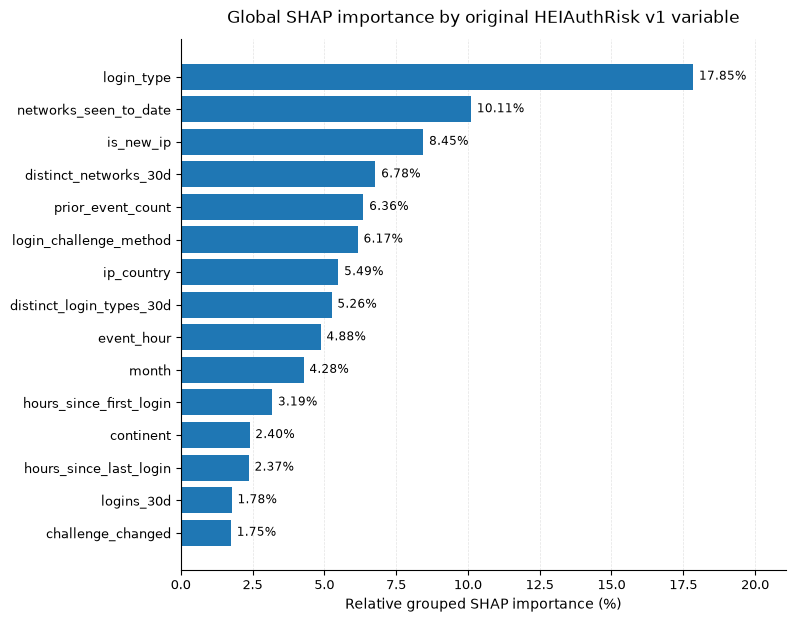

In [22]:

plot_df = source_importance.head(15).sort_values(
    "relative_percent",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(9.6, 6.8))
bars = ax.barh(
    plot_df["source_variable"],
    plot_df["relative_percent"],
)

for bar, pct in zip(bars, plot_df["relative_percent"]):
    ax.text(
        bar.get_width() + 0.20,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.2f}%",
        va="center",
        ha="left",
        fontsize=8.5,
    )

ax.set_xlabel("Relative grouped SHAP importance (%)")
ax.set_ylabel("")
ax.set_title(
    "Global SHAP importance by original HEIAuthRisk v1 variable",
    pad=12,
)
ax.tick_params(axis="y", labelsize=9)
ax.tick_params(axis="x", labelsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.35)
ax.set_axisbelow(True)
ax.set_xlim(0, plot_df["relative_percent"].max() * 1.18)

fig.subplots_adjust(left=0.34, right=0.97, top=0.90, bottom=0.12)

fig.savefig(
    FIGURE_DIR / "shap_global_source_variables.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "shap_global_source_variables.pdf",
    bbox_inches="tight",
)
plt.show()


## 14. Agregação por grupos conceituais do CIAuthE

In [24]:

FEATURE_GROUPS = {
    # Temporal
    "event_hour": "Temporal",
    "day_of_week": "Temporal",
    "month": "Temporal",
    "is_weekend": "Temporal",

    # Activity/history
    "prior_event_count": "Activity/history",
    "hours_since_last_login": "Activity/history",
    "hours_since_first_login": "Activity/history",
    "logins_24h": "Activity/history",
    "logins_7d": "Activity/history",
    "logins_30d": "Activity/history",
    "login_rate_30d": "Activity/history",
    "active_days_30d": "Activity/history",

    # Network
    "ip_version": "Network",
    "is_new_ip": "Network",
    "ip_changed": "Network",
    "distinct_networks_24h": "Network",
    "distinct_networks_7d": "Network",
    "distinct_networks_30d": "Network",
    "networks_seen_to_date": "Network",

    # Geography
    "ip_country": "Geography",
    "continent": "Geography",
    "is_new_country": "Geography",
    "country_changed": "Geography",
    "is_new_continent": "Geography",
    "continent_changed": "Geography",
    "distinct_countries_24h": "Geography",
    "distinct_countries_7d": "Geography",
    "distinct_countries_30d": "Geography",
    "distinct_countries_to_date": "Geography",

    # Authentication
    "login_type": "Authentication",
    "login_challenge_method": "Authentication",
    "is_new_login_type": "Authentication",
    "login_type_changed": "Authentication",
    "is_new_challenge": "Authentication",
    "challenge_changed": "Authentication",
    "distinct_login_types_30d": "Authentication",
    "distinct_challenges_30d": "Authentication",
}


assert set(source_importance["source_variable"]).issubset(FEATURE_GROUPS)

group_importance = source_importance.copy()
group_importance["group"] = (
    group_importance["source_variable"].map(FEATURE_GROUPS)
)

group_importance = (
    group_importance
    .groupby("group", as_index=False)["mean_abs_shap"]
    .sum()
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

group_importance["relative_percent"] = (
    group_importance["mean_abs_shap"]
    / group_importance["mean_abs_shap"].sum()
    * 100
)

group_importance.to_csv(
    OUTPUT_DIR / "shap_group_importance.csv",
    index=False,
)

display(group_importance)


,group,mean_abs_shap,relative_percent
0,Authentication,2.580089,34.465117
1,Network,2.113268,28.229275
2,Activity/history,1.281567,17.119314
3,Temporal,0.817143,10.915482
4,Geography,0.694021,9.270812


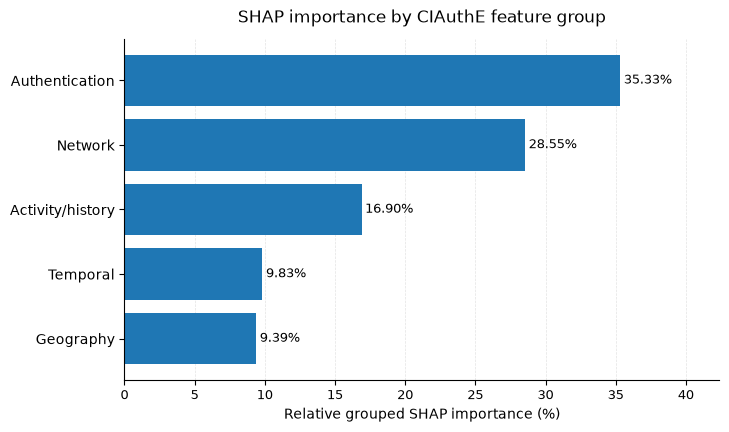

In [ ]:

plot_groups = group_importance.sort_values(
    "relative_percent",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.barh(
    plot_groups["group"],
    plot_groups["relative_percent"],
)

for bar, pct in zip(bars, plot_groups["relative_percent"]):
    ax.text(
        bar.get_width() + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.2f}%",
        va="center",
        ha="left",
        fontsize=9,
    )

ax.set_xlabel("Relative grouped SHAP importance (%)")
ax.set_ylabel("")
ax.set_title("SHAP importance by HEIAuthRisk v1 feature group", pad=12)
ax.tick_params(axis="y", labelsize=10)
ax.tick_params(axis="x", labelsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.35)
ax.set_axisbelow(True)
ax.set_xlim(0, plot_groups["relative_percent"].max() * 1.20)

fig.subplots_adjust(left=0.27, right=0.97, top=0.88, bottom=0.17)

fig.savefig(
    FIGURE_DIR / "shap_group_importance.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "shap_group_importance.pdf",
    bbox_inches="tight",
)
plt.show()



## 15. Dependence plots para variáveis numéricas

Esta seção seleciona automaticamente as quatro variáveis numéricas originais com maior `mean(|SHAP|)` e mostra como o valor observado se relaciona com a contribuição do modelo.


Top numeric variables: ['networks_seen_to_date', 'is_new_ip', 'distinct_networks_30d', 'prior_event_count']


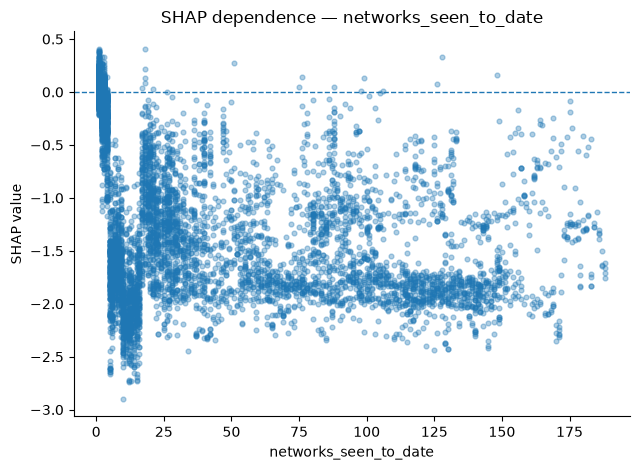

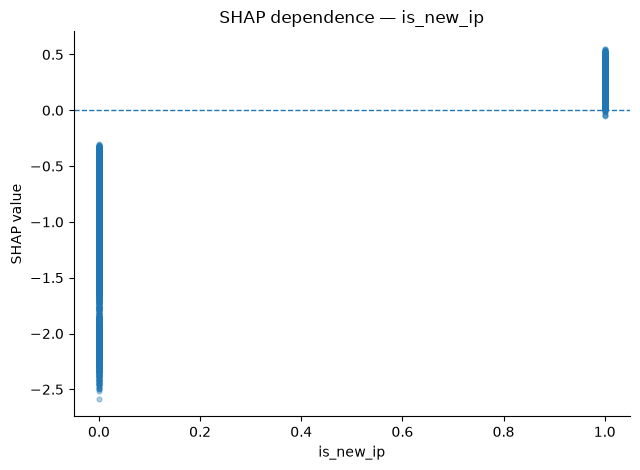

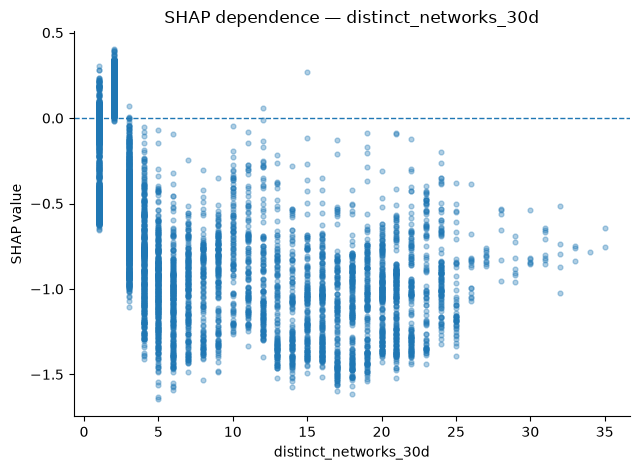

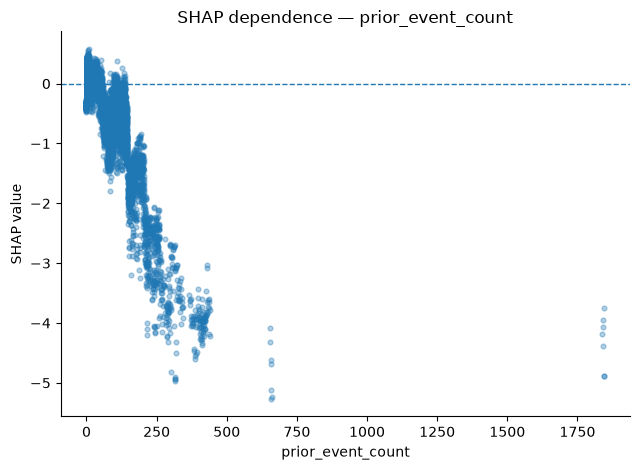

In [25]:

top_numeric_sources = (
    source_importance[
        source_importance["source_variable"].isin(NUMERIC_FEATURES)
    ]
    .head(4)["source_variable"]
    .tolist()
)

print("Top numeric variables:", top_numeric_sources)

clean_names_array = np.asarray(clean_feature_names)

for source_feature in top_numeric_sources:
    matches = np.where(clean_names_array == source_feature)[0]
    if len(matches) != 1:
        print("Skipping ambiguous feature:", source_feature)
        continue

    j = int(matches[0])

    fig, ax = plt.subplots(figsize=(6.5, 4.8))
    ax.scatter(
        X_shap_dense[:, j],
        shap_values.values[:, j],
        alpha=0.35,
        s=12,
    )
    ax.axhline(0, linewidth=1, linestyle="--")
    ax.set_xlabel(source_feature)
    ax.set_ylabel("SHAP value")
    ax.set_title(f"SHAP dependence — {source_feature}")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()

    safe_name = source_feature.replace("/", "_")
    fig.savefig(
        FIGURE_DIR / f"shap_dependence_{safe_name}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()



## 16. Local explanations at event level

As explicações locais mostram como diferentes atributos contribuem para a saída do modelo em eventos individuais.

Para evitar seleção subjetiva, são utilizados dois eventos do escopo SHAP:

1. o evento com maior saída do modelo para a classe `provider_suspicious=1`;
2. o evento com menor saída para essa classe.

O `event_id` é preservado apenas para identificação da observação explicada; ele não é utilizado como preditor.

Os gráficos *waterfall* mostram quais variáveis deslocam a saída do XGBoost em direção à classe 1 ou à classe 0.


In [26]:

shap_scores = model.predict_proba(X_shap_t)[:, 1]

highest_position = int(np.argmax(shap_scores))
lowest_position = int(np.argmin(shap_scores))

selected_local_events = pd.DataFrame([
    {
        "selection_rule": "highest_score",
        "position": highest_position,
        "event_id": metadata_shap.loc[highest_position, "event_id"],
        "event_time_hour_utc": metadata_shap.loc[
            highest_position, "event_time_hour_utc"
        ],
        "observed_provider_suspicious": int(
            metadata_shap.loc[highest_position, TARGET]
        ),
        "class1_model_score": float(
            shap_scores[highest_position]
        ),
    },
    {
        "selection_rule": "lowest_score",
        "position": lowest_position,
        "event_id": metadata_shap.loc[lowest_position, "event_id"],
        "event_time_hour_utc": metadata_shap.loc[
            lowest_position, "event_time_hour_utc"
        ],
        "observed_provider_suspicious": int(
            metadata_shap.loc[lowest_position, TARGET]
        ),
        "class1_model_score": float(
            shap_scores[lowest_position]
        ),
    },
])

selected_local_events.to_csv(
    OUTPUT_DIR / "local_selected_events.csv",
    index=False,
)

display(selected_local_events)


,selection_rule,position,event_id,event_time_hour_utc,observed_provider_suspicious,class1_model_score
0,highest_score,9413,Eb3b2e01f8c515fe9a15d324ac858af73,2026-07-29 15:00:00+00:00,1,0.997347
1,lowest_score,10388,Edbfd9bd334124272450db341541bc212,2026-08-08 06:00:00+00:00,0,0.000001



### 16.1 Local contribution tables

As tabelas abaixo identificam as contribuições de maior magnitude nos dois eventos selecionados.

`direction` indica apenas a direção da contribuição dentro do modelo:

- `toward provider_suspicious=1`;
- `toward provider_suspicious=0`.

Isso não deve ser interpretado como evidência causal de ataque.


In [27]:

def local_contribution_table(position, selection_rule, max_rows=12):
    table = pd.DataFrame({
        "transformed_feature": clean_feature_names,
        "feature_value": X_shap_dense[position],
        "shap_value": shap_values.values[position],
    })

    table["abs_shap"] = table["shap_value"].abs()

    table["direction"] = np.where(
        table["shap_value"] > 0,
        "toward provider_suspicious=1",
        np.where(
            table["shap_value"] < 0,
            "toward provider_suspicious=0",
            "neutral",
        ),
    )

    event_row = selected_local_events.loc[
        selected_local_events["selection_rule"].eq(selection_rule)
    ].iloc[0]

    table = (
        table
        .sort_values("abs_shap", ascending=False)
        .head(max_rows)
        .reset_index(drop=True)
    )

    table.insert(0, "selection_rule", selection_rule)
    table.insert(1, "event_id", event_row["event_id"])
    table.insert(
        2,
        "class1_model_score",
        float(event_row["class1_model_score"]),
    )
    table.insert(
        3,
        "observed_provider_suspicious",
        int(event_row["observed_provider_suspicious"]),
    )

    return table


local_highest = local_contribution_table(
    highest_position,
    "highest_score",
)

local_lowest = local_contribution_table(
    lowest_position,
    "lowest_score",
)

local_highest.to_csv(
    OUTPUT_DIR / "local_explanation_highest_score.csv",
    index=False,
)

local_lowest.to_csv(
    OUTPUT_DIR / "local_explanation_lowest_score.csv",
    index=False,
)

print("Highest-score event:")
display(local_highest)

print("\nLowest-score event:")
display(local_lowest)


Highest-score event:


,selection_rule,event_id,class1_model_score,observed_provider_suspicious,transformed_feature,feature_value,shap_value,abs_shap,direction
0,highest_score,Eb3b2e01f8c515fe9a15d324ac858af73,0.997347,1,login_challenge_method_password|idv_any_phone,1.000000,3.734416,3.734416,toward provider_suspicious=1
1,highest_score,Eb3b2e01f8c515fe9a15d324ac858af73,0.997347,1,is_new_challenge,1.000000,1.160190,1.160190,toward provider_suspicious=1
2,highest_score,Eb3b2e01f8c515fe9a15d324ac858af73,0.997347,1,challenge_changed,1.000000,0.670894,0.670894,toward provider_suspicious=1
3,highest_score,Eb3b2e01f8c515fe9a15d324ac858af73,0.997347,1,login_challenge_method_password,0.000000,0.625850,0.625850,toward provider_suspicious=1
4,highest_score,Eb3b2e01f8c515fe9a15d324ac858af73,0.997347,1,networks_seen_to_date,21.000000,-0.584248,0.584248,toward provider_suspicious=0
5,highest_score,Eb3b2e01f8c515fe9a15d324ac858af73,0.997347,1,login_challenge_method_none,0.000000,0.387067,0.387067,toward provider_suspicious=1
6,highest_score,Eb3b2e01f8c515fe9a15d324ac858af73,0.997347,1,month,7.000000,0.329935,0.329935,toward provider_suspicious=1
7,highest_score,Eb3b2e01f8c515fe9a15d324ac858af73,0.997347,1,ip_country_Brazil,0.000000,-0.300429,0.300429,toward provider_suspicious=0
8,highest_score,Eb3b2e01f8c515fe9a15d324ac858af73,0.997347,1,distinct_networks_30d,3.000000,-0.287901,0.287901,toward provider_suspicious=0
9,highest_score,Eb3b2e01f8c515fe9a15d324ac858af73,0.997347,1,login_type_reauth,0.000000,-0.267716,0.267716,toward provider_suspicious=0



Lowest-score event:


,selection_rule,event_id,class1_model_score,observed_provider_suspicious,transformed_feature,feature_value,shap_value,abs_shap,direction
0,lowest_score,Edbfd9bd334124272450db341541bc212,0.000001,0,login_type_exchange,1.000000,-3.193613,3.193613,toward provider_suspicious=0
1,lowest_score,Edbfd9bd334124272450db341541bc212,0.000001,0,networks_seen_to_date,43.000000,-2.141850,2.141850,toward provider_suspicious=0
2,lowest_score,Edbfd9bd334124272450db341541bc212,0.000001,0,distinct_networks_30d,16.000000,-0.998701,0.998701,toward provider_suspicious=0
3,lowest_score,Edbfd9bd334124272450db341541bc212,0.000001,0,logins_30d,49.000000,-0.960199,0.960199,toward provider_suspicious=0
4,lowest_score,Edbfd9bd334124272450db341541bc212,0.000001,0,login_challenge_method_none,1.000000,-0.937796,0.937796,toward provider_suspicious=0
5,lowest_score,Edbfd9bd334124272450db341541bc212,0.000001,0,month,8.000000,-0.831706,0.831706,toward provider_suspicious=0
6,lowest_score,Edbfd9bd334124272450db341541bc212,0.000001,0,prior_event_count,125.000000,-0.798267,0.798267,toward provider_suspicious=0
7,lowest_score,Edbfd9bd334124272450db341541bc212,0.000001,0,hours_since_first_login,"2,918.414400",-0.553919,0.553919,toward provider_suspicious=0
8,lowest_score,Edbfd9bd334124272450db341541bc212,0.000001,0,login_type_reauth,0.000000,-0.553193,0.553193,toward provider_suspicious=0
9,lowest_score,Edbfd9bd334124272450db341541bc212,0.000001,0,is_new_ip,0.000000,-0.529471,0.529471,toward provider_suspicious=0


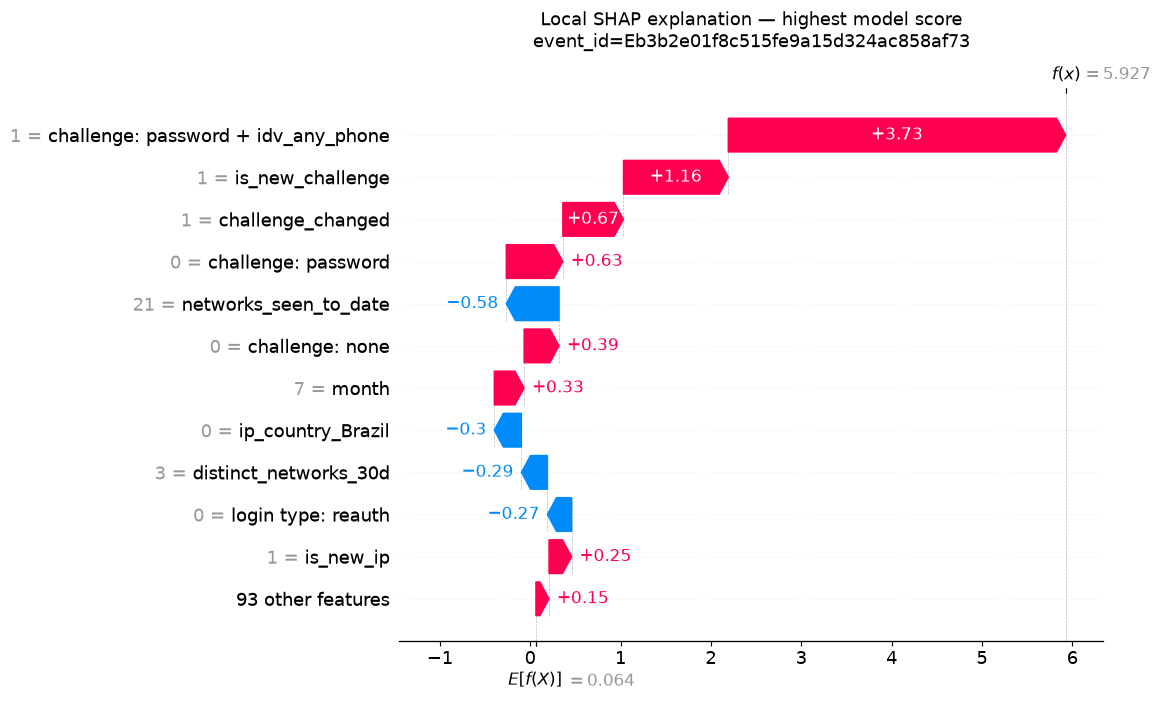

In [28]:

shap.plots.waterfall(
    shap_values_plot[highest_position],
    max_display=12,
    show=False,
)

fig = plt.gcf()
fig.set_size_inches(12.8, 7.2)

ax = plt.gca()
ax.set_title(
    (
        "Local SHAP explanation — highest model score\n"
        f"event_id={selected_local_events.loc[selected_local_events['selection_rule'].eq('highest_score'), 'event_id'].iloc[0]}"
    ),
    fontsize=13,
    pad=14,
)
ax.tick_params(axis="y", labelsize=9)

fig.subplots_adjust(
    left=0.42,
    right=0.97,
    top=0.88,
    bottom=0.12,
)

fig.savefig(
    FIGURE_DIR / "shap_waterfall_highest_score.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "shap_waterfall_highest_score.pdf",
    bbox_inches="tight",
)
plt.show()


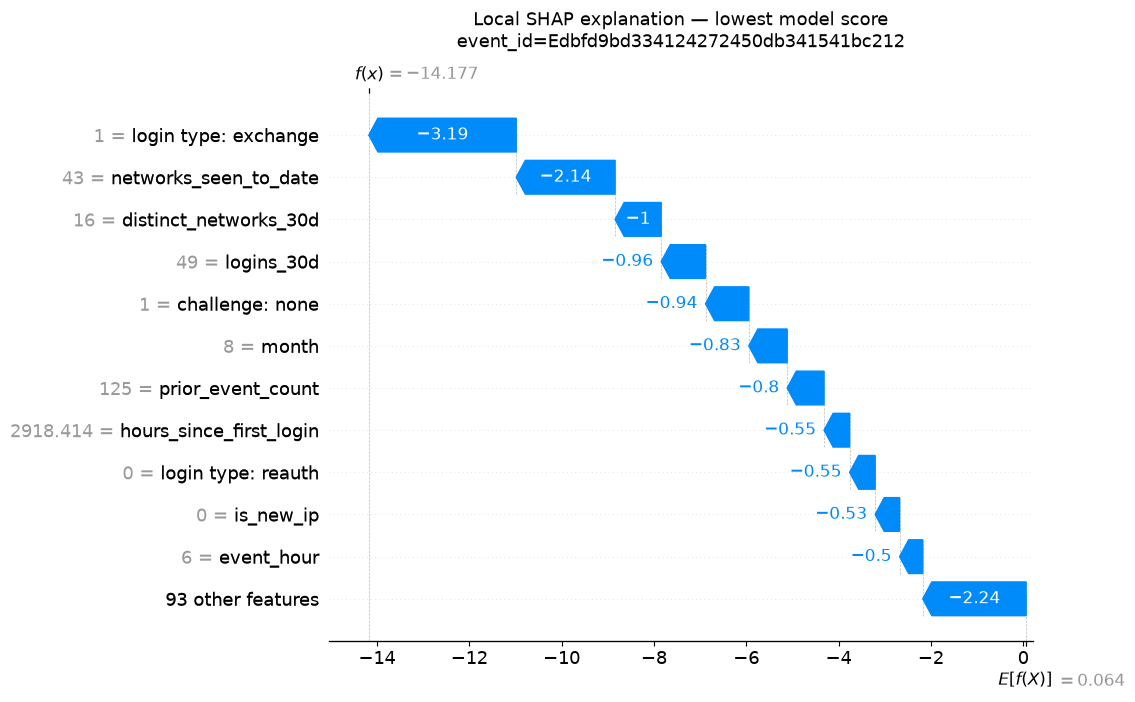

In [29]:

shap.plots.waterfall(
    shap_values_plot[lowest_position],
    max_display=12,
    show=False,
)

fig = plt.gcf()
fig.set_size_inches(12.8, 7.2)

ax = plt.gca()
ax.set_title(
    (
        "Local SHAP explanation — lowest model score\n"
        f"event_id={selected_local_events.loc[selected_local_events['selection_rule'].eq('lowest_score'), 'event_id'].iloc[0]}"
    ),
    fontsize=13,
    pad=14,
)
ax.tick_params(axis="y", labelsize=9)

fig.subplots_adjust(
    left=0.42,
    right=0.97,
    top=0.88,
    bottom=0.12,
)

fig.savefig(
    FIGURE_DIR / "shap_waterfall_lowest_score.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "shap_waterfall_lowest_score.pdf",
    bbox_inches="tight",
)
plt.show()


## 17. Exportação do modelo e resumo da análise

In [30]:

model.save_model(
    OUTPUT_DIR / "xgboost_provider_suspicious.json"
)

joblib.dump(
    preprocessor,
    OUTPUT_DIR / "xgboost_preprocessor.joblib",
)


def json_safe(value):
    """
    Convert pandas/numpy objects to values accepted by json.dumps().
    """
    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):
        return float(value)

    if isinstance(value, np.bool_):
        return bool(value)

    if value is pd.NA:
        return None

    if isinstance(value, dict):
        return {
            str(k): json_safe(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            json_safe(v)
            for v in value
        ]

    return value


highest_event_summary = (
    selected_local_events.loc[
        selected_local_events["selection_rule"].eq("highest_score")
    ]
    .iloc[0]
    .to_dict()
)

lowest_event_summary = (
    selected_local_events.loc[
        selected_local_events["selection_rule"].eq("lowest_score")
    ]
    .iloc[0]
    .to_dict()
)


summary = {
    "dataset": "HEIAuthRisk v1 public release",
    "events": int(len(df)),
    "actors": int(df["actor_pseudo_id"].nunique()),
    "target": TARGET,
    "model": "XGBoost",
    "split": (
        "temporal 70/15/15 approximately, "
        "preserving complete UTC hours"
    ),
    "rolling_temporal_validation": False,
    "use_class_weight": bool(USE_CLASS_WEIGHT),
    "scale_pos_weight": float(scale_pos_weight),
    "roc_auc_test": float(roc_auc),
    "pr_auc_test": float(pr_auc),
    "shap_scope": SHAP_SCOPE,
    "shap_backend": "xgboost_pred_contribs_sparse",
    "shap_additivity_max_error": float(shap_additivity_error),
    "shap_approximate": bool(SHAP_APPROXIMATE),
    "shap_max_rows": SHAP_MAX_ROWS,
    "shap_explained_events": int(shap_n),
    "top_source_variables": (
        source_importance
        .head(10)
        .to_dict(orient="records")
    ),
    "group_importance": (
        group_importance
        .to_dict(orient="records")
    ),
    "local_highest_score_event": highest_event_summary,
    "local_lowest_score_event": lowest_event_summary,
}

summary = json_safe(summary)

(OUTPUT_DIR / "xgboost_shap_summary.json").write_text(
    json.dumps(
        summary,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print("Outputs written to:")
print(OUTPUT_DIR)
print("\nSummary JSON serialization: PASS")


Outputs written to:
E:\Developer\HEIAuthRisk\public\data\xgboost_shap_outputs

Summary JSON serialization: PASS



## 18. Como interpretar os resultados

Para o artigo, as saídas mais importantes são:

### 1. Global explanation of feature importance

`shap_global_source_variables.csv` e `shap_global_source_variables.pdf` mostram quais variáveis originais do CIAuthE concentram maior contribuição média absoluta no XGBoost.

`shap_beeswarm.pdf` complementa a análise ao mostrar magnitude e direção das contribuições das variáveis transformadas.

### 2. Feature-group synthesis

`shap_group_importance.csv` e `shap_group_importance.pdf` mostram como a importância se distribui entre:

- Temporal;
- Activity/history;
- Network;
- Geography;
- Authentication.

### 3. Local explanations at event level

`local_selected_events.csv` registra os dois eventos selecionados deterministicamente.

`local_explanation_highest_score.csv` e `local_explanation_lowest_score.csv` identificam as maiores contribuições positivas e negativas para cada evento.

Os gráficos `shap_waterfall_highest_score.pdf` e `shap_waterfall_lowest_score.pdf` fornecem a representação visual das explicações locais.

### Cuidados metodológicos

1. SHAP explica o modelo, não causalidade.
2. As contribuições desta versão são calculadas diretamente pelo XGBoost sobre a matriz sparse original (`pred_contribs=True`).
3. Alta importância SHAP não implica causalidade.
4. Variáveis correlacionadas podem dividir a atribuição entre si.
5. Para resultados por variável original, as contribuições das dummies são somadas por evento antes de calcular `mean(|SHAP|)`.
6. `provider_suspicious` é a variável-alvo e nunca entra como preditor.
7. `provider_suspicious=1` significa sinalização operacional do provedor, não ataque confirmado.
8. `provider_suspicious=0` não significa evento comprovadamente legítimo.
9. Se `USE_CLASS_WEIGHT=True`, a saída deve ser tratada como score discriminativo, não automaticamente como probabilidade calibrada.

### Escopo temporal desta versão

Este notebook utiliza **somente o temporal holdout principal** (treino/validação/teste em ordem cronológica).

**Não há rolling temporal validation nesta versão.**
